# Model Machine Learning: Decision Tree Regressor
### Prediksi Harga Rumah (Kaggle Competition)

Notebook ini merupakan versi Jupyter Notebook yang rapi dan terstruktur dari script `DecisionTreeRegressor.py`.

---

### Alur Kerja & Langkah-Langkah:
1. **Import Library**: Memuat pustaka yang dibutuhkan (`pandas`, `sklearn`, `matplotlib`, `seaborn`).
2. **Load Data**: Membaca dataset latih (`train.csv`) dan dataset uji (`test.csv`).
3. **Eksplorasi Singkat Data (EDA)**: Meninjau bentuk data dan target harga rumah.
4. **Pemilihan Fitur (Feature Selection)**: Memilih 10 fitur utama yang digunakan untuk melatih model.
5. **Train-Validation Split**: Membagi data menjadi data latih (*training*) dan data validasi (*validation*).
6. **Hyperparameter Tuning (`max_leaf_nodes`)**: Menguji nilai `max_leaf_nodes` dari 2 hingga 199 untuk menemukan model dengan MAE terkecil.
7. **Pelatihan Model Akhir & Evaluasi MAE**: Melatih model dengan ukuran daun optimal dan mencetak Mean Absolute Error.
8. **Prediksi Data Test & Pembuatan File Submission**: Melakukan prediksi pada data test dan menyimpannya ke `Submission.csv`.


## 1. Import Library
Mengimpor modul-modul yang dibutuhkan:
- `pandas` untuk manipulasi data tabular.
- `DecisionTreeRegressor` dari `sklearn.tree` untuk membuat model pohon keputusan regresi.
- `mean_absolute_error` dari `sklearn.metrics` untuk menghitung rata-rata selisih absolut antara nilai aktual dan prediksi.
- `train_test_split` dari `sklearn.model_selection` untuk membagi dataset.
- `matplotlib.pyplot` dan `seaborn` untuk visualisasi.


In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import os


## 2. Pemuatan Dataset (Train & Test)
File dibagi menjadi dua:
- **`train.csv`**: Digunakan untuk melatih model. Berisi fitur dan kolom target `SalePrice`.
- **`test.csv`**: Digunakan sebagai data uji utama untuk kompetisi. Kolom `SalePrice` tidak ada pada file ini.


In [2]:
# 1. Ambil file path csv, baca file dan masukkan ke variabel 
model_file_path = "train.csv" if os.path.exists("train.csv") else r"D:\file baru\mendata\machine learning competition\train.csv"
model_file_path_test = "test.csv" if os.path.exists("test.csv") else r"D:\file baru\mendata\machine learning competition\test.csv"

model_data = pd.read_csv(model_file_path)
model_data_test = pd.read_csv(model_file_path_test)

print(f"Bentuk data train: {model_data.shape}")
print(f"Bentuk data test : {model_data_test.shape}")


Bentuk data train: (1460, 81)
Bentuk data test : (1459, 80)


## 3. Eksplorasi Singkat Data (EDA Cepat)
Melihat 5 baris pertama data train dan data test untuk memastikan file termuat dengan benar.


In [3]:
# Pratinjau data train
display(model_data.head())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Pratinjau data test
display(model_data_test.head())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


## 4. Penentuan Target (`y`) dan Pemilihan Fitur (`X`)
Target prediksi adalah harga rumah (`SalePrice`). 
Sebanyak 10 fitur utama dipilih untuk memprediksi harga tersebut:
- `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `1stFlrSF`, `YearBuilt`, `YearRemodAdd`, `FullBath`, `TotRmsAbvGrd`, `LotArea`.


In [5]:
y = model_data.SalePrice

model_features = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 
    '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'FullBath', 
    'TotRmsAbvGrd', 'LotArea'
]

X = model_data[model_features]
test_data_X = model_data_test[model_features]

print("=== 5 Baris Pertama Fitur Latih (X) ===")
display(X.head())


=== 5 Baris Pertama Fitur Latih (X) ===


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,1stFlrSF,YearBuilt,YearRemodAdd,FullBath,TotRmsAbvGrd,LotArea
0,7,1710,2,856,856,2003,2003,2,8,8450
1,6,1262,2,1262,1262,1976,1976,2,6,9600
2,7,1786,2,920,920,2001,2002,2,6,11250
3,7,1717,3,756,961,1915,1970,1,7,9550
4,8,2198,3,1145,1145,2000,2000,2,9,14260


## 5. Pembagian Data Latih dan Validasi (`train_test_split`)
Membagi data fitur `X` dan target `y` menjadi data pelatihan (`train_X`, `train_y`) dan data validasi (`val_X`, `val_y`). 
`random_state=1` digunakan untuk menjamin hasil pembagian data selalu konsisten setiap kali kode dijalankan.


In [6]:
train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=1)

print(f"Jumlah sampel train_X: {train_X.shape[0]}")
print(f"Jumlah sampel val_X  : {val_X.shape[0]}")


Jumlah sampel train_X: 1095
Jumlah sampel val_X  : 365


## 6. Hyperparameter Tuning: Menemukan `max_leaf_nodes` Terbaik
Mendefinisikan fungsi `get_mae()` untuk menghitung nilai MAE pada model `DecisionTreeRegressor` dengan batas jumlah daun (*leaf nodes*) tertentu.
Kita menguji nilai dari **2 hingga 199** untuk mencari nilai yang memberikan galat terkecil (mencegah *underfitting* dan *overfitting*).


In [7]:
# fungsi get_mae(menganalisis model dengan maksimal jumlah node)
def get_mae(max_leaf_nodes, train_X, val_X, train_y, val_y):
    model = DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes, random_state=1)
    model.fit(train_X, train_y)
    predicst_val = model.predict(val_X)
    mae = mean_absolute_error(val_y, predicst_val)
    return(mae)

candidate_max_leaf_nodes = []

for i in range(2, 200):
    candidate_max_leaf_nodes.append(i)
scores = {}

for max_leaf_nodes in candidate_max_leaf_nodes:
    my_mae = get_mae(max_leaf_nodes, train_X, val_X, train_y, val_y)
  
    # simpan hasil leaf terbaik
    scores[max_leaf_nodes] = my_mae

best_size = min(scores, key=scores.get)

print(f"\nmodel dengan nodes terbaik adalah {best_size}")
print(f"MAE pada nodes terbaik: {scores[best_size]:,.2f}")



model dengan nodes terbaik adalah 69
MAE pada nodes terbaik: 22,539.35


### Visualisasi Perbandingan MAE terhadap Jumlah Node
Grafik ini memperlihatkan bagaimana nilai MAE menurun tajam saat node ditingkatkan dari 2, kemudian mencapai titik terendah (optimal), dan mulai meningkat kembali akibat overfitting.


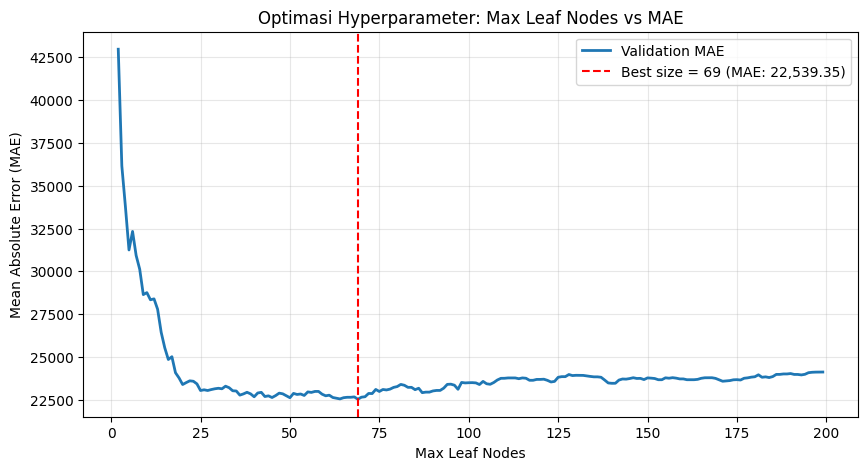

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(list(scores.keys()), list(scores.values()), color='#1f77b4', lw=2, label='Validation MAE')
plt.axvline(best_size, color='red', linestyle='--', label=f'Best size = {best_size} (MAE: {scores[best_size]:,.2f})')
plt.title("Optimasi Hyperparameter: Max Leaf Nodes vs MAE")
plt.xlabel("Max Leaf Nodes")
plt.ylabel("Mean Absolute Error (MAE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 7. Melatih Ulang Model Akhir & Evaluasi MAE
Melatih ulang model Decision Tree dengan `max_leaf_nodes=best_size` dan menghitung galat akhir pada data validasi.


In [9]:
# Fit ulang model akhir
final_model = DecisionTreeRegressor(max_leaf_nodes=best_size, random_state=1)
final_model.fit(train_X, train_y)
val_predict = final_model.predict(val_X)
galat = mean_absolute_error(val_y, val_predict)

print("===== MEAN ABSOLUTE ERROR MODEL ADALAH =====")
print(galat)


===== MEAN ABSOLUTE ERROR MODEL ADALAH =====
22539.349536959515


## 8. Prediksi pada Data Test & Pembuatan File Submission
Menggunakan `final_model` untuk memprediksi harga rumah pada data uji (`test_data_X`).
Membuat DataFrame hasil prediksi, membandingkan pratinjau data, dan menyimpannya ke dalam file **`Submission.csv`**.


In [10]:
prediksi_akhir = final_model.predict(test_data_X)

data_awal = pd.DataFrame({
    'ID' : model_data_test['Id'],
    'SalePrice' : y
})

data_prediksi = pd.DataFrame({
    'ID': model_data_test['Id'],
    'SalePrice': prediksi_akhir
})

print("===== PERBANDINGAN DATA AWAL DENGAN DATA PREDIKSI =====")
print(data_awal.head())
print(data_prediksi.head())

# Simpan hasil ke file CSV
data_prediksi.to_csv('Submission.csv', index=False)
print("\nHasil prediksi berhasil disimpan ke 'Submission.csv'")


===== PERBANDINGAN DATA AWAL DENGAN DATA PREDIKSI =====
       ID  SalePrice
0  1461.0     208500
1  1462.0     181500
2  1463.0     223500
3  1464.0     140000
4  1465.0     250000
     ID      SalePrice
0  1461  121780.182927
1  1462  131756.756757
2  1463  141032.200000
3  1464  184192.117647
4  1465  204805.090909

Hasil prediksi berhasil disimpan ke 'Submission.csv'


### Visualisasi Hasil Prediksi Harga Rumah
Melihat sebaran harga rumah yang diprediksi oleh model Decision Tree.


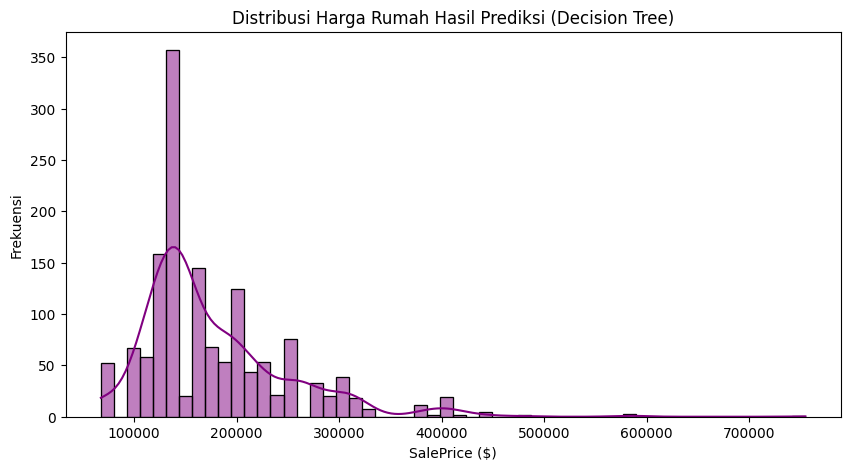

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(data_prediksi['SalePrice'], kde=True, color='purple')
plt.title("Distribusi Harga Rumah Hasil Prediksi (Decision Tree)")
plt.xlabel("SalePrice ($)")
plt.ylabel("Frekuensi")
plt.show()
